In [1]:
import pandas as pd

# 1. Đọc file Excel
file_path = '123.xlsx'
try:
    df = pd.read_excel(file_path)
    print(f"Đã đọc thành công file: {file_path}\n")
    
    # 2. Số hàng và số cột
    so_hang = df.shape[0]
    so_cot = df.shape[1]
    print(f"- Số hàng (rows): {so_hang}")
    print(f"- Số cột (columns): {so_cot}")

    # 3. Số lượng dòng bị duplicate (trùng lặp hoàn toàn)
    so_duplicate = df.duplicated().sum()
    print(f"- Số dòng duplicate: {so_duplicate}")

    # 4. Số hàng có missing (NaN) trên 50% dữ liệu
    # axis=1 nghĩa là tính theo hàng, thresh=len(df.columns)*0.5 nghĩa là giữ lại hàng có ít nhất 50% dữ liệu không bị missing
    # Do đó, những hàng bị loại bỏ (bị drop) chính là những hàng có missing > 50%
    # Cách đếm: Đếm số lượng NaN trên mỗi hàng, chia cho tổng số cột, nếu > 0.5 thì tính là 1
    so_hang_missing_50 = (df.isnull().sum(axis=1) / so_cot > 0.5).sum()
    print(f"- Số hàng có missing trên 50% dữ liệu: {so_hang_missing_50}")

    # 5. Các cột có nhiều missing nhất
    print("- Các cột có nhiều missing nhất:")
    missing_counts = df.isnull().sum()
    max_missing = missing_counts.max()
    
    if max_missing == 0:
        print("  + Không có cột nào bị missing dữ liệu.")
    else:
        # Lấy danh sách các cột có số lượng missing bằng với giá trị lớn nhất
        top_missing_cols = missing_counts[missing_counts == max_missing].index.tolist()
        for col in top_missing_cols:
            print(f"  + Cột '{col}': {max_missing} giá trị missing")

except FileNotFoundError:
    print(f"Lỗi: Không tìm thấy file '{file_path}'. Hãy kiểm tra lại xem file có nằm cùng thư mục không.")
except Exception as e:
    print(f"Có lỗi xảy ra: {e}")

Đã đọc thành công file: 123.xlsx

- Số hàng (rows): 7974
- Số cột (columns): 33
- Số dòng duplicate: 0
- Số hàng có missing trên 50% dữ liệu: 0
- Các cột có nhiều missing nhất:
  + Cột 'Ancillary_Revenue': 271 giá trị missing


In [2]:
# Xem số lượng missing theo từng cột
missing_per_col = df.isnull().sum()
print(missing_per_col[missing_per_col > 0])  # Chỉ in các cột có missing

Ancillary_Revenue    271
Catering_Cost        265
Handling_Cost        256
dtype: int64


In [6]:
# 1. Impute Ancillary_Revenue
df['Ancillary_Revenue'] = df['Ancillary_Revenue'].fillna(df['Total_Revenue'] - df['Ticket_Revenue'])

# 2. Impute Catering_Cost
# Lấy Total Cost trừ đi tổng các cột bắt đầu bằng 'Cost' (ngoại trừ Catering_Cost)
other_costs = df.filter(like='Cost').drop(columns=['Catering_Cost']).sum(axis=1)
df['Catering_Cost'] = df['Catering_Cost'].fillna(df['Total_Cost'] - other_costs)

# 1. Tính Handling_Cost trước (Tổng Cost - Tổng các Cost khác, loại trừ Handling và Catering)
other_costs_1 = df.filter(like='Cost').drop(columns=['Handling_Cost', 'Catering_Cost']).sum(axis=1)
df['Handling_Cost'] = df['Handling_Cost'].fillna(df['Total_Cost'] - other_costs_1)

# Kiểm tra lại
print(df[['Ancillary_Revenue', 'Catering_Cost', 'Handling_Cost']].isnull().sum())

Ancillary_Revenue    0
Catering_Cost        0
Handling_Cost        0
dtype: int64


In [7]:
# Xuất file ra định dạng Excel, bỏ qua cột index
df.to_excel('123-cleaned.xlsx', index=False)
print("Đã xuất file thành công: 123-cleaned.xlsx")

Đã xuất file thành công: 123-cleaned.xlsx


In [8]:
# Danh sách 15 cột chi phí bạn cung cấp (có thể sửa lại tên nếu file thực tế dùng dấu cách)
cost_cols = [
    'Fuel_Cost', 'Maintenance_Cost', 'Crew_Cost', 'Depreciation_Cost', 
    'Insurance_Cost', 'Airport_Fees', 'Catering_Cost', 'Handling_Cost', 
    'Navigation_Fees', 'Sales_Distribution_Cost', 'Passenger_Service_Cost', 
    'Overhead_Cost', 'Marketing_Cost', 'IT_Systems_Cost'
]

# 1. Tính lại Handling_Cost: Total_Cost - (tổng 13 cột còn lại) -> lấy abs
# Lưu ý: drop cả Handling_Cost và Catering_Cost để tránh tính trùng lặp
other_costs_handling = df[cost_cols].drop(columns=['Handling_Cost', 'Catering_Cost']).sum(axis=1)
# Chỉ điền vào những chỗ đang bị NaN (nếu bạn muốn ghi đè toàn bộ thì bỏ .fillna)
df['Handling_Cost'] = df['Handling_Cost'].fillna((df['Total_Cost'] - other_costs_handling).abs())

# 2. Tính lại Catering_Cost: Total_Cost - (tổng 14 cột còn lại, đã có Handling_Cost chuẩn) -> lấy abs
other_costs_catering = df[cost_cols].drop(columns=['Catering_Cost']).sum(axis=1)
df['Catering_Cost'] = df['Catering_Cost'].fillna((df['Total_Cost'] - other_costs_catering).abs())

# 3. Xử lý triệt để: Đề phòng các cột khác trong file gốc cũng bị âm, ta có thể bọc abs() cho toàn bộ cột chi phí
for col in cost_cols + ['Total_Cost', 'Ancillary_Revenue', 'Total_Revenue', 'Ticket_Revenue']:
    if col in df.columns:
        df[col] = df[col].abs()

# Kiểm tra lại xem còn missing hoặc âm không
print("Số lượng missing còn lại:\n", df[['Ancillary_Revenue', 'Catering_Cost', 'Handling_Cost']].isnull().sum())
print("\nGiá trị nhỏ nhất của các cột Cost (phải >= 0):\n", df[cost_cols].min())


Số lượng missing còn lại:
 Ancillary_Revenue    0
Catering_Cost        0
Handling_Cost        0
dtype: int64

Giá trị nhỏ nhất của các cột Cost (phải >= 0):
 Fuel_Cost                  2592.62
Maintenance_Cost           1380.00
Crew_Cost                   936.00
Depreciation_Cost          2040.00
Insurance_Cost              336.00
Airport_Fees               2000.79
Catering_Cost              1398.40
Handling_Cost              2000.04
Navigation_Fees             483.57
Sales_Distribution_Cost    2143.11
Passenger_Service_Cost     1750.11
Overhead_Cost              3750.19
Marketing_Cost              608.62
IT_Systems_Cost             923.26
dtype: float64


In [11]:
import numpy as np
import pandas as pd

# 1. Tạo DataFrame chứa bảng khoảng cách
distance_data = {
    'Destination': ['FRA', 'SIN', 'CDG', 'BKK', 'HKG', 'KUL', 'BOM', 'KHI', 'DEL', 'LHE', 
                    'JFK', 'IST', 'SYD', 'HYD', 'MCT', 'BAH', 'CMB', 'BLR', 'MEL', 'MAA', 
                    'DOH', 'ORD', 'KWI', 'SFO', 'LHR', 'LAX', 'RUH', 'JED', 'AMM', 'CAI'],
    'Distance': [4848, 5847, 5245, 4909, 5931, 555, 1927, 1191, 2188, 1988, 
                 11022, 303, 12039, 255, 349, 487, 3286, 2695, 11636, 2935, 
                 378, 11662, 854, 13041, 5504, 1342, 874, 1701, 2023, 2419]
}
df_distance = pd.DataFrame(distance_data)

# 2. Merge bảng khoảng cách vào df chính (dựa trên cột Destination)
# Lưu ý: Nếu df của bạn đã có cột Distance cũ, ta nên xóa nó đi trước để tránh trùng lặp
if 'Distance' in df.columns:
    df = df.drop(columns=['Distance'])

df = df.merge(df_distance, on='Destination', how='left')

# Kiểm tra xem có dòng nào bị thiếu Distance sau khi merge không
missing_dist = df['Distance'].isnull().sum()
if missing_dist > 0:
    print(f"Cảnh báo: Có {missing_dist} dòng không tìm thấy Distance tương ứng.")

# 3. Tính RASK và CASK
# Công thức: Doanh thu (hoặc Chi phí) / (Số ghế * Khoảng cách)
df['RASK'] = df['Total_Revenue'] / (df['Aircraft_Capacity'] * df['Distance'])
df['CASK'] = df['Total_Cost'] / (df['Aircraft_Capacity'] * df['Distance'])

# 4. Tạo các chỉ số phân tích khác
df['Break_Even_LF'] = df['Total_Cost'] / (df['Total_Revenue'] / df['Load_Factor'])
df['Break_Even_LF'] = df['Break_Even_LF'].clip(upper=1.0) # Giới hạn BEL tối đa là 1
df['Safety_Margin_LF'] = df['Load_Factor'] - df['Break_Even_LF']
df['RASK_CASK_Spread'] = df['RASK'] - df['CASK']
df['Ancillary_per_Pax'] = df['Ancillary_Revenue'] / df['Passengers']

print("Đã tính xong RASK, CASK và các chỉ số. Mẫu dữ liệu:")
print(df[['Destination', 'Distance', 'RASK', 'CASK', 'RASK_CASK_Spread']].head())

Đã tính xong RASK, CASK và các chỉ số. Mẫu dữ liệu:
  Destination  Distance      RASK      CASK  RASK_CASK_Spread
0         ORD     11662  0.100520  0.109659         -0.009139
1         HYD       255  2.167269  1.633862          0.533407
2         CDG      5245  0.439006  0.181812          0.257194
3         DEL      2188  0.222387  0.175897          0.046490
4         RUH       874  0.232156  0.296090         -0.063934


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_28996\4065091618.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Route_Category', y='Break_Even_LF', data=df, palette='Set2')


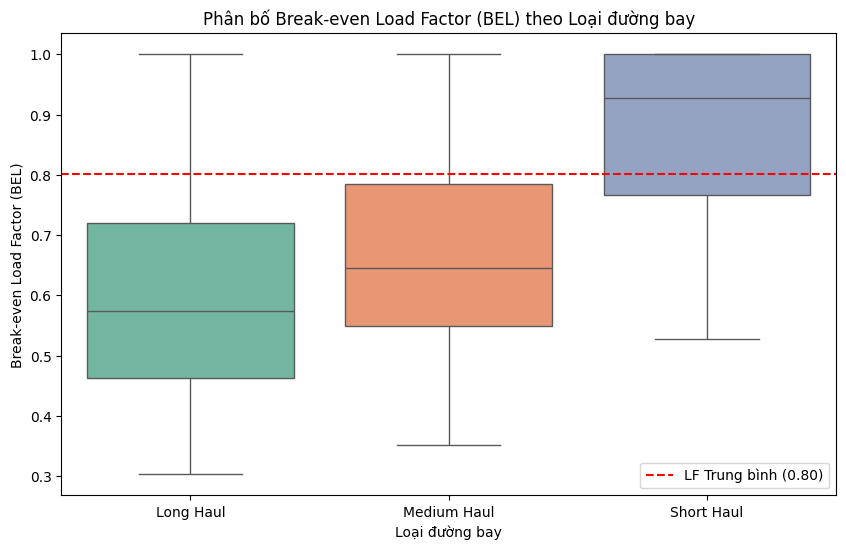

In [12]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Route_Category', y='Break_Even_LF', data=df, palette='Set2')
plt.axhline(y=df['Load_Factor'].mean(), color='red', linestyle='--', label=f'LF Trung bình ({df["Load_Factor"].mean():.2f})')
plt.title('Phân bố Break-even Load Factor (BEL) theo Loại đường bay')
plt.ylabel('Break-even Load Factor (BEL)')
plt.xlabel('Loại đường bay')
plt.legend()
plt.show()

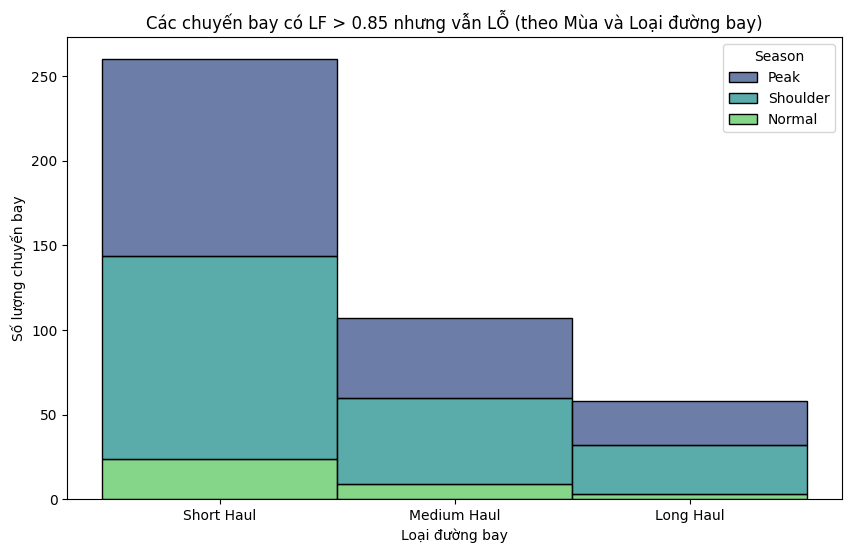

Tổng số chuyến bay 'đầy nhưng lỗ': 425
Tỷ lệ trên tổng số chuyến bay: 5.33%


In [16]:
# Lọc các chuyến bay có LF cao nhưng lỗ
high_lf_loss = df[(df['Load_Factor'] > 0.85) & (df['PM'] < 0)]

plt.figure(figsize=(10, 6))
sns.histplot(data=high_lf_loss, x='Route_Category', hue='Season', multiple='stack', palette='viridis')
plt.title('Các chuyến bay có LF > 0.85 nhưng vẫn LỖ (theo Mùa và Loại đường bay)')
plt.xlabel('Loại đường bay')
plt.ylabel('Số lượng chuyến bay')
plt.show()

print(f"Tổng số chuyến bay 'đầy nhưng lỗ': {len(high_lf_loss)}")
print(f"Tỷ lệ trên tổng số chuyến bay: {len(high_lf_loss)/len(df)*100:.2f}%")

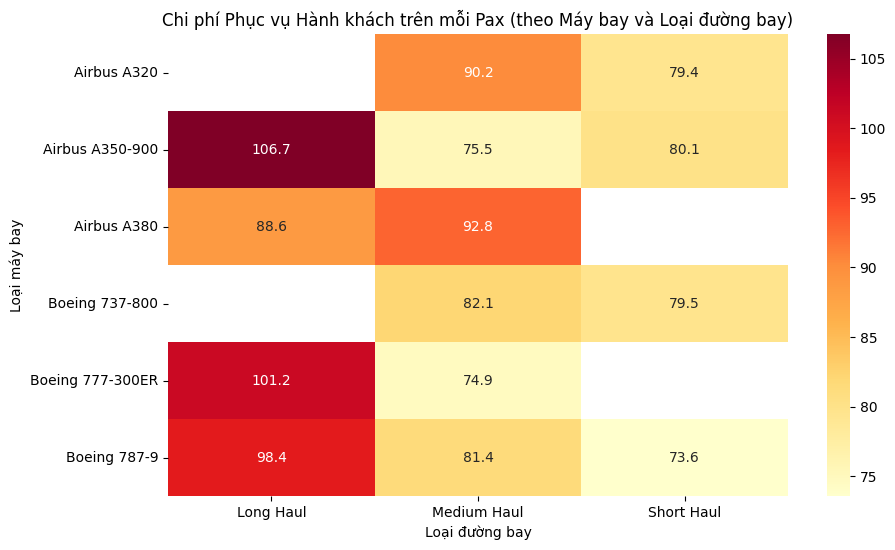

In [17]:
# Tính chi phí phục vụ hành khách trên mỗi pax
df['Pax_Service_Cost_per_Pax'] = (df['Catering_Cost'] + df['Handling_Cost'] + df['Passenger_Service_Cost']) / df['Passengers']

# Tạo bảng pivot
pivot_table = df.pivot_table(index='Aircraft_Type', columns='Route_Category', 
                             values='Pax_Service_Cost_per_Pax', aggfunc='mean')

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_table, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Chi phí Phục vụ Hành khách trên mỗi Pax (theo Máy bay và Loại đường bay)')
plt.xlabel('Loại đường bay')
plt.ylabel('Loại máy bay')
plt.show()

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Define Features and Target
# Exclude all revenue, cost, and profit-related columns to avoid data leakage
exclude_cols = [
    'Flight_Number', 'Flight_Date', 'Origin', 'Destination', 'Route', # IDs & Dates
    'Ticket_Revenue', 'Ancillary_Revenue', 'Total_Revenue', # Revenue
    'Fuel_Cost', 'Maintenance_Cost', 'Crew_Cost', 'Depreciation_Cost', 'Insurance_Cost', 
    'Airport_Fees', 'Catering_Cost', 'Handling_Cost', 'Navigation_Fees', 
    'Sales_Distribution_Cost', 'Passenger_Service_Cost', 'Overhead_Cost', 
    'Marketing_Cost', 'IT_Systems_Cost', 'Total_Cost', # Cost
    'Profit', 'PM', 'RASK', 'CASK', 'RASK_CASK_Spread', 'Break_Even_LF', 'Safety_Margin_LF', 'Ancillary_per_Pax' # Derived financials
]

# Keep only planning/operational features
features = [col for col in df.columns if col not in exclude_cols]
X = df[features].copy()
y = df['PM'].copy()

# 2. Handle Categorical Variables (One-Hot Encoding)
X = pd.get_dummies(X, drop_first=True)

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")
print(f"Number of features after encoding: {X_train.shape[1]}")

Training set: (6379, 17), Test set: (1595, 17)
Number of features after encoding: 17


In [24]:
# 1. Initialize and Optimize Random Forest using RandomizedSearchCV
rf_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}

rf = RandomForestRegressor(random_state=42)
rf_search = RandomizedSearchCV(rf, rf_params, n_iter=20, cv=3, scoring='r2', random_state=42, n_jobs=-1, verbose=1)
rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_
print("\n--- Random Forest Best Params ---")
print(best_rf.get_params())

Fitting 3 folds for each of 20 candidates, totalling 60 fits

--- Random Forest Best Params ---
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 20, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 4, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [26]:
# 1. Initialize and Optimize XGBoost using RandomizedSearchCV
xgb_params = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7, 9],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.2]
}

xgb = XGBRegressor(random_state=42, objective='reg:squarederror')
xgb_search = RandomizedSearchCV(xgb, xgb_params, n_iter=20, cv=3, scoring='r2', random_state=42, n_jobs=-1, verbose=1)
xgb_search.fit(X_train, y_train)

best_xgb = xgb_search.best_estimator_
print("\n--- XGBoost Best Params ---")
print(best_xgb.get_params())

Fitting 3 folds for each of 20 candidates, totalling 60 fits

--- XGBoost Best Params ---
{'objective': 'reg:squarederror', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 1.0, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': None, 'feature_types': None, 'feature_weights': None, 'gamma': 0, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 3, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 100, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': 0.8, 'tree_method': None, 'validate_parameters': None, 'verbosity': Non

In [27]:
def evaluate_model(model, X_test, y_test, model_name):
    preds = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    print(f"\n--- {model_name} Performance on Test Set ---")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE : {mae:.4f}")
    print(f"R²  : {r2:.4f}")
    
evaluate_model(best_rf, X_test, y_test, "Random Forest")
evaluate_model(best_xgb, X_test, y_test, "XGBoost")


--- Random Forest Performance on Test Set ---
RMSE: 0.2101
MAE : 0.1591
R²  : 0.7020

--- XGBoost Performance on Test Set ---
RMSE: 0.2069
MAE : 0.1583
R²  : 0.7111


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_28996\4271639902.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rf_importances.values, y=rf_importances.index, ax=axes[0], palette='viridis')
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_28996\4271639902.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=xgb_importances.values, y=xgb_importances.index, ax=axes[1], palette='magma')


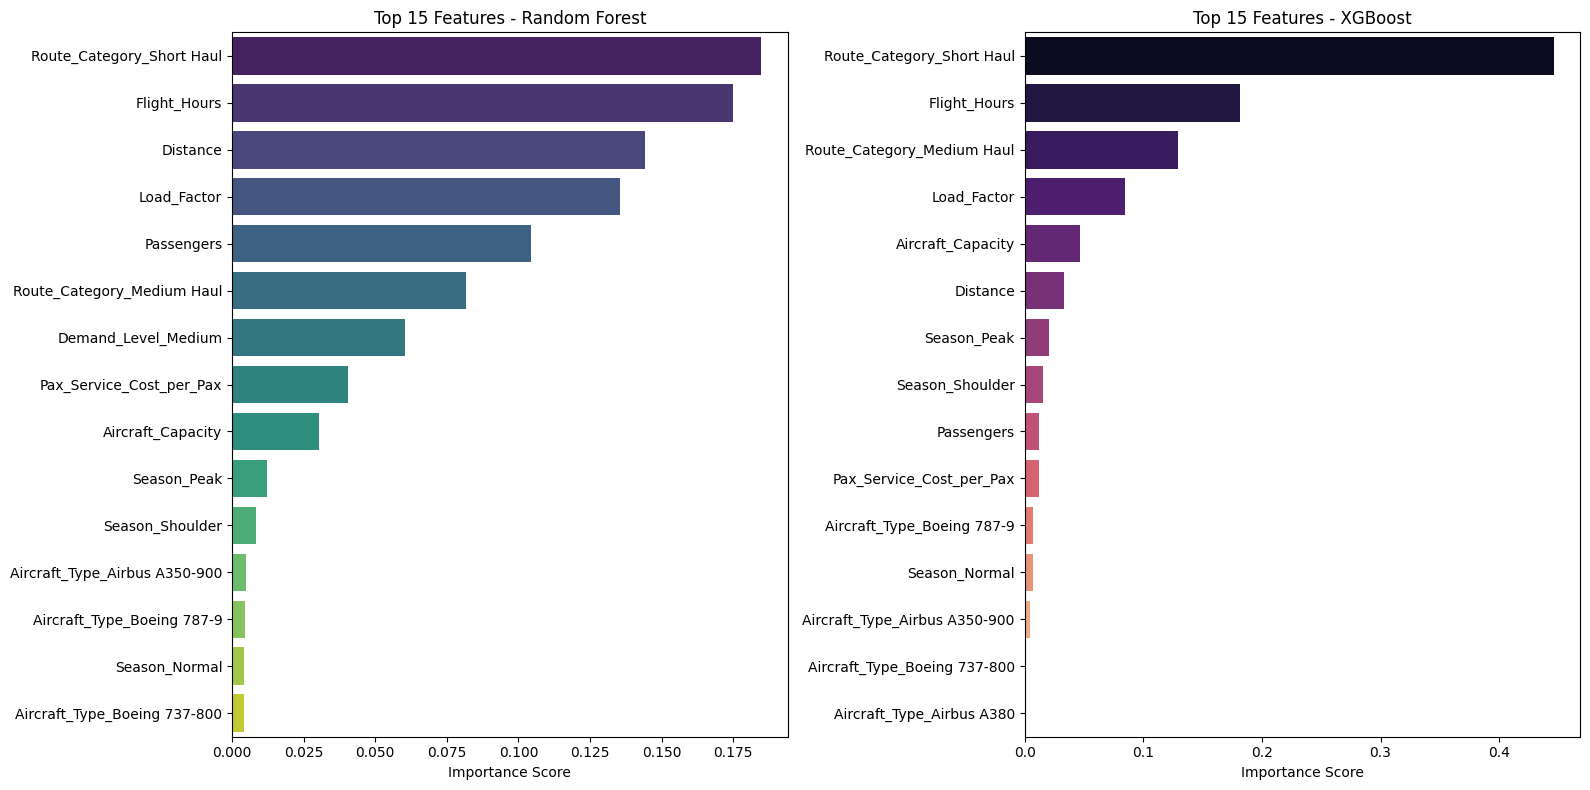

In [28]:
# 1. Extract Feature Importances
rf_importances = pd.Series(best_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
xgb_importances = pd.Series(best_xgb.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)

# 2. Plotting
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Random Forest Plot
sns.barplot(x=rf_importances.values, y=rf_importances.index, ax=axes[0], palette='viridis')
axes[0].set_title('Top 15 Features - Random Forest')
axes[0].set_xlabel('Importance Score')
axes[0].set_ylabel('')

# XGBoost Plot
sns.barplot(x=xgb_importances.values, y=xgb_importances.index, ax=axes[1], palette='magma')
axes[1].set_title('Top 15 Features - XGBoost')
axes[1].set_xlabel('Importance Score')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()